# Industrial Anomaly Detection Challenge - AutoVI from Renault

## Dataset Description

### Extract the dataset
First, extract the raw image data from the AutoVI dataset. Display the 3 image categories before futher analysis.

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_splitting").is_dir())
RAW  = REPO / "data" / "raw" / "autovi_npz" / "_extracted"

assert RAW.is_dir(), (
    f"{RAW} not found. The extracted images are produced by:\n"
    "  python data_splitting/autovi.py --zips data/raw/autovi/*.zip \\\n"
    "      --out data/raw/autovi_npz --keep-extracted"
)
print("repo:", REPO)
print("raw :", RAW)
print("categories:", sorted(p.name for p in RAW.iterdir() if p.is_dir()))


repo: /home/alex/Industrial-Anomaly-Detection
raw : /home/alex/Industrial-Anomaly-Detection/data/raw/autovi_npz/_extracted
categories: ['engine_wiring', 'pipe_clip', 'pipe_staple']


### Train and test
Split the dataset into train and test datasets. Use the anomaly images for the test set only, as the classification will use unsupervised learning methods. AutoVI has no anomaly in the train set by default: every defect image is in its test set.

In [2]:
rows = []
for cat_dir in sorted(p for p in RAW.iterdir() if p.is_dir()):
    for split in ("train", "test"):
        split_dir = cat_dir / split
        if not split_dir.is_dir():
            continue
        for folder in sorted(p for p in split_dir.iterdir() if p.is_dir()):
            for png in sorted(folder.glob("*.png")):
                rows.append({
                    "category":     cat_dir.name,
                    "autovi_split": split,             # AutoVI's OWN split
                    "folder":       folder.name,
                    "label":        "normal" if folder.name == "good" else "anomaly",
                    "defect_type":  None if folder.name == "good" else folder.name,
                    "path":         png,
                })

df = pd.DataFrame(rows)
print(f"{len(df)} images")
df.groupby(["category", "autovi_split", "folder"]).size()


1920 images


category       autovi_split  folder     
engine_wiring  test          blue_hoop        5
                             cardboard        5
                             fastening      277
                             good           285
                             multiple        33
                             obstruction      2
               train         good           285
pipe_clip      test          good           195
                             operator         1
                             unclipped      141
               train         good           195
pipe_staple    test          good           188
                             missing        117
               train         good           191
dtype: int64

In [3]:
proof = pd.crosstab(df["autovi_split"], df["label"])
print(proof)

label         anomaly  normal
autovi_split                 
test              581     668
train               0     671


### About the dataset
The dataset contains images from Renault's factory from 3 categories. The grids below
show what the model actually sees: one grid per category, with the normal (`good`) images
on the top row and each defect type on its own row underneath.

We have the following defect categories:
```
AutoVI
├── engine_wiring
│   ├── good
│   ├── fastening
│   ├── multiple
│   ├── blue_hoop
│   ├── cardboard
│   └── obstruction
├── pipe_clip
│   ├── good
│   ├── unclipped
│   └── operator
└── pipe_staple
    ├── good
    └── missing
```

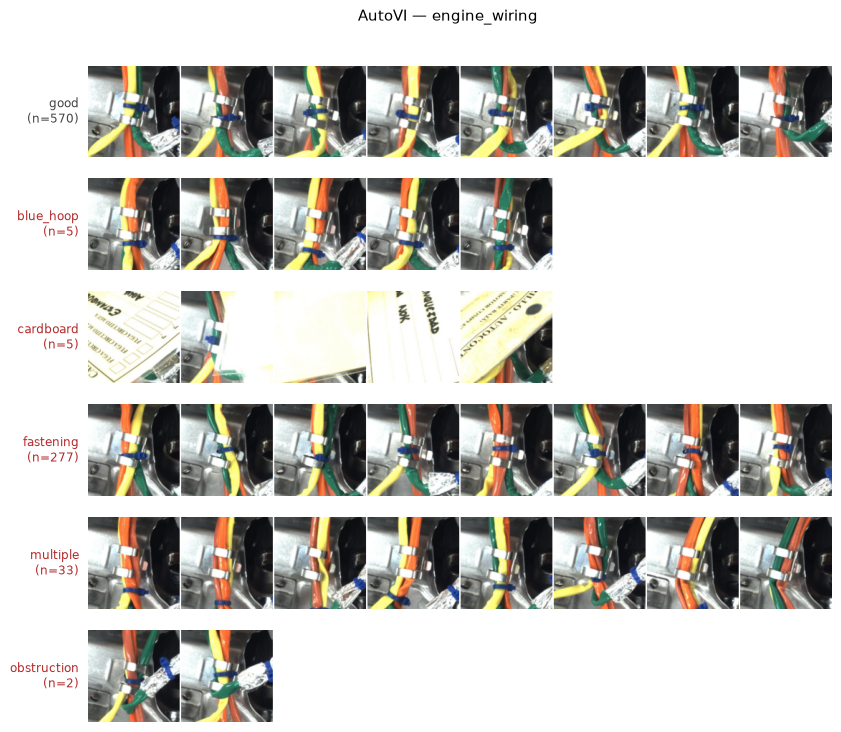

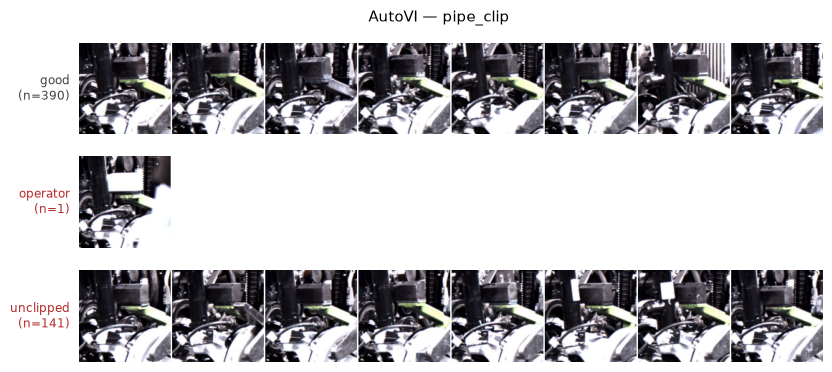

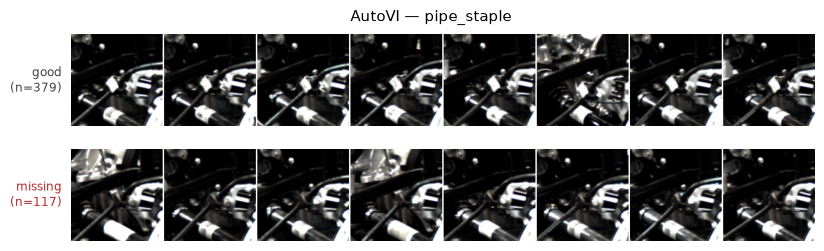

In [4]:
N_COLS, PAD, THUMB = 8, 2, 128
rng = np.random.default_rng(42)


def montage(paths, n_cols=N_COLS, size=THUMB, pad=PAD):
    """Tile images into one (rows*size, cols*size, 3) uint8 canvas."""
    n_rows = int(np.ceil(len(paths) / n_cols))
    canvas = np.full((n_rows * (size + pad) - pad,
                      n_cols * (size + pad) - pad, 3), 255, np.uint8)
    for i, p in enumerate(paths):
        with Image.open(p) as im:
            tile = np.asarray(im.convert("RGB").resize((size, size), Image.BILINEAR))
        r, c = divmod(i, n_cols)
        canvas[r * (size + pad):r * (size + pad) + size,
               c * (size + pad):c * (size + pad) + size] = tile
    return canvas


for cat, g in df.groupby("category"):
    # 'good' first, then each defect type -- one row-block per class
    classes = ["good"] + sorted(g.loc[g["label"] == "anomaly", "defect_type"].unique())
    fig, axes = plt.subplots(len(classes), 1, squeeze=False,
                             figsize=(N_COLS * 1.2, len(classes) * 1.35))

    for ax, name in zip(axes.ravel(), classes):
        sub = g[g["folder"] == name]
        take = rng.choice(sub["path"].values, min(N_COLS, len(sub)), replace=False)
        ax.imshow(montage(take))
        ax.set_axis_off()
        ax.text(-0.012, 0.5, f"{name}\n(n={len(sub)})", transform=ax.transAxes,
                ha="right", va="center", fontsize=8.5,
                color="#444" if name == "good" else "#B4292A")

    fig.suptitle(f"AutoVI — {cat}", fontsize=11, y=1.0)
    fig.subplots_adjust(hspace=0.05, top=0.94)
    plt.show()


Check the class-imbalance and the anomaly rate of the dataset. The engine_wiring categoty holds almost half of the images at 46.5%, while the other 2 categories pipe_clip and pipe_staple are balanced between each other at 27.7% and 25.8%.

In [5]:
print(f"total images     : {len(df)}")
print(f"categories       : {df['category'].nunique()}")
print(f"defect types     : {df['defect_type'].nunique()}")
print(f"overall anomaly %: {(df['label'] == 'anomaly').mean():.1%}\n")

per_cat = pd.crosstab(df["category"], df["label"])[["normal", "anomaly"]]
per_cat["total"]     = per_cat.sum(axis=1)
per_cat["dataset_%"] = (100 * per_cat["total"] / len(df)).round(1)
per_cat["anomaly_%"] = (100 * per_cat["anomaly"] / per_cat["total"]).round(1)
per_cat


total images     : 1920
categories       : 3
defect types     : 8
overall anomaly %: 30.3%



label,normal,anomaly,total,dataset_%,anomaly_%
category,,,,,
engine_wiring,570,322,892,46.5,36.1
pipe_clip,390,142,532,27.7,26.7
pipe_staple,379,117,496,25.8,23.6


### Anomaly rate
The entire dataset showcases ~30% anomaly rate, a comfortable ratio for an unsupervised anomaly detection model. Otherwise, a low anomaly rate (e.g. 1-2%) the detection rate couldn't perform better than a trivial classifier, so accuracy would be an unsuitable performance metric (Provost, 2000). The 3 categories' (engine_wiring, pipe_clip, pipe_staple) anomaly rate is also imbalanced, engine_wiring holding 36% of the defect images.

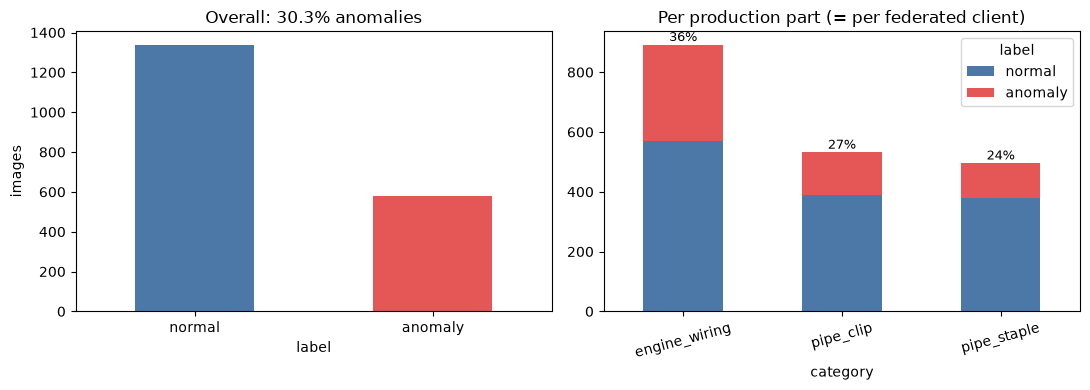

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

df["label"].value_counts().plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"], rot=0)
ax[0].set_title(f"Overall: {(df.label == 'anomaly').mean():.1%} anomalies")
ax[0].set_ylabel("images")

per_cat[["normal", "anomaly"]].plot.bar(ax=ax[1], stacked=True,
                                        color=["#4C78A8", "#E45756"], rot=15)
ax[1].set_title("Per production part (= per federated client)")
for i, (_, r) in enumerate(per_cat.iterrows()):
    ax[1].text(i, r["total"] + 12, f"{r['anomaly_%']:.0f}%", ha="center", fontsize=9)

fig.tight_layout()


The most prominent anomaly type, engine_wiring fastening, stands at 14.43% of all images and 1/3 of the category's images. Some defects stand the majority in the category anomalies set &mdash; for pipe_staple all anomalies are 'missing', pipe_clip	'unclipped' at 99% of the category images and engine_wiring	'fastening' at ~86%. engine_wiring category has a more diverse anomaly set, but the other defect types represent a small percentage of images (less than 4%, obstruction, blue_hoop and cardboard less than 1%).

In [7]:
tax = (df[df["label"] == "anomaly"]
       .groupby(["category", "defect_type"]).size().rename("n").reset_index())
tax["% of all images"] = (100 * tax["n"] / len(df)).round(2)
cat_totals = df.groupby("category").size()
tax["% of category images"] = (100 * tax["n"] / tax["category"].map(cat_totals)).round(2)
# share of this defect type among its category's anomalies only
anom_totals = df[df["label"] == "anomaly"].groupby("category").size()
tax["% of category anomalies"] = (100 * tax["n"] / tax["category"].map(anom_totals)).round(2)
tax.sort_values("n")

,category,defect_type,n,% of all images,% of category images,% of category anomalies
5,pipe_clip,operator,1,0.05,0.19,0.70
4,engine_wiring,obstruction,2,0.10,0.22,0.62
0,engine_wiring,blue_hoop,5,0.26,0.56,1.55
1,engine_wiring,cardboard,5,0.26,0.56,1.55
3,engine_wiring,multiple,33,1.72,3.70,10.25
7,pipe_staple,missing,117,6.09,23.59,100.00
6,pipe_clip,unclipped,141,7.34,26.50,99.30
2,engine_wiring,fastening,277,14.43,31.05,86.02


### Image properties
Resolution is uniform (400×400), colour mode is not. Keep in mind to convert all the images to RGB for tensor size consistency in the model with the engine_wiring class.

In [8]:
sizes, modes = [], []
for p in df["path"]:
    with Image.open(p) as im:
        sizes.append(im.size)
        modes.append(im.mode)

df["width"]  = [s[0] for s in sizes]
df["height"] = [s[1] for s in sizes]
df["mode"]   = modes

print("resolutions :", df[["width", "height"]].drop_duplicates().to_dict("records"))
print("colour modes:", df["mode"].unique().tolist())
print("on disk     : %.0f MB" % (sum(p.stat().st_size for p in df["path"]) / 1e6))
print()
print(pd.crosstab(df["category"], df["mode"]))


resolutions : [{'width': 400, 'height': 400}]
colour modes: ['RGB', 'RGBA']
on disk     : 492 MB

mode           RGB  RGBA
category                
engine_wiring  892     0
pipe_clip        0   532
pipe_staple      0   496


Keeping the native image size for UPB cluster training.

In [9]:
SIZE = 400

def load(path, size=SIZE):
    """PNG (400x400, RGB or RGBA) -> (size, size, 3) uint8."""
    with Image.open(path) as im:
        im = im.convert("RGB").resize((size, size), Image.BILINEAR)
        return np.asarray(im, dtype=np.uint8)

X = np.stack([load(p) for p in df["path"]])
print(X.shape, X.dtype, "| %.0f MB in RAM" % (X.nbytes / 1e6))


(1920, 400, 400, 3) uint8 | 922 MB in RAM


### Pixel statistics
Analyze the averate difference and deviation in pixels. See how different the images actually are.

In [10]:
stats = np.empty((len(df), 4), dtype=np.float32)

for i, p in enumerate(df["path"]):
    with Image.open(p) as im:
        g = np.asarray(im.convert("RGB"), dtype=np.float32).mean(axis=2) / 255.0
    stats[i] = (g.mean(), g.std(), np.percentile(g, 5), np.percentile(g, 95))

df[["mean_px", "std_px", "p5", "p95"]] = stats

summary = (df.groupby("category")[["mean_px", "std_px", "p5", "p95"]]
             .agg(["mean", "std"]).round(3))
summary.loc["GLOBAL"] = (df[["mean_px", "std_px", "p5", "p95"]]
                         .agg(["mean", "std"]).T.stack().round(3))
summary

mean_px        std_px            p5           p95       
                 mean    std   mean    std   mean    std   mean    std
category                                                              
engine_wiring   0.471  0.040  0.307  0.014  0.068  0.031  0.990  0.013
pipe_clip       0.428  0.045  0.374  0.007  0.014  0.011  1.000  0.000
pipe_staple     0.194  0.032  0.294  0.019  0.000  0.000  0.983  0.030
GLOBAL          0.388  0.122  0.322  0.035  0.036  0.038  0.991  0.019

The 3 categories distinguish heavily in brightness. `pipe_staple` has darker images compared to the other 2 categories (mean 0.19 vs 0.43 for `pipe_clip` and 0.47 for `engine_wiring`). Within a category brightness is stable (std 0.03–0.05), while the global std is 0.12, so the variation comes from the part, not the lighting of individual images.

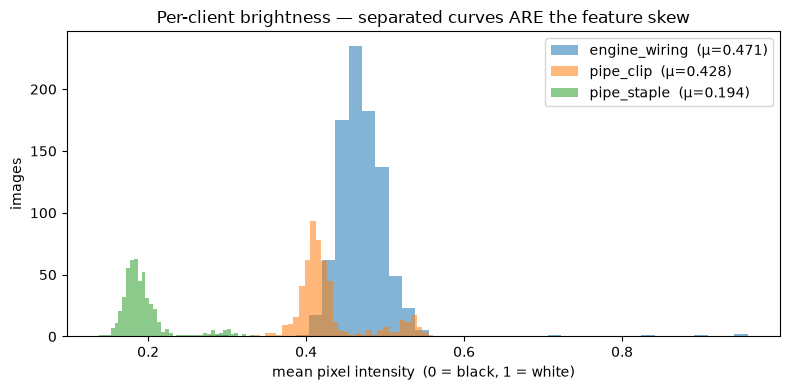

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
for cat, sub in df.groupby("category"):
    ax.hist(sub["mean_px"], bins=40, alpha=0.55,
            label=f"{cat}  (μ={sub['mean_px'].mean():.3f})")
ax.set_xlabel("mean pixel intensity  (0 = black, 1 = white)")
ax.set_ylabel("images")
ax.set_title("Per-client brightness — separated curves ARE the feature skew")
ax.legend()
fig.tight_layout()


### Distinquishable
Could a model tell which station an image came from, using only the statistics above? The results below (and the raw images) show the categories have quite distinct images (they are feature-skewed).

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

feat = df[["mean_px", "std_px", "p5", "p95"]].to_numpy()
acc  = cross_val_score(LogisticRegression(max_iter=2000),
                       feat, df["category"].to_numpy(), cv=5).mean()

print(f"client identified from 4 pixel statistics: {acc:.1%}  (chance = 33.3%)")


client identified from 4 pixel statistics: 97.3%  (chance = 33.3%)


### Duplicates and leakage 
Some of the train images belong also to the test set.


In [13]:
digests = []
for p in df["path"]:
    with Image.open(p) as im:
        digests.append(hashlib.md5(np.asarray(im.convert("RGB")).tobytes()).hexdigest())
df["pixel_md5"] = digests

dup = df.duplicated("pixel_md5", keep=False)
print(f"images belonging to a duplicate group : {dup.sum()}")
print(f"distinct duplicate groups             : {df.loc[dup, 'pixel_md5'].nunique()}")
print(f"redundant copies (removable)          : {df.duplicated('pixel_md5').sum()}\n")

# WHERE are the copies? That is what decides whether it is dangerous.
groups = (df[dup].groupby("pixel_md5")
          .agg(n=("path", "size"),
               folders=("folder", lambda s: " + ".join(sorted(set(s)))),
               cats=("category", lambda s: " ".join(sorted(set(s))))))
print(groups.groupby(["cats", "folders"]).agg(groups=("n", "size"), images=("n", "sum")))


images belonging to a duplicate group : 146
distinct duplicate groups             : 73
redundant copies (removable)          : 73

                         groups  images
cats          folders                  
engine_wiring good           60     120
pipe_clip     unclipped      13      26


No image belongs to more than 1 category.

In [15]:
spans = df[dup].groupby("pixel_md5")["category"].nunique()
print("duplicate groups spanning more than one category:", (spans > 1).sum())   # -> 0


duplicate groups spanning more than one category: 0


### Near-duplicates
Analyze the similarity of the images beloging to the same category. We first drop color, resize to 8x8, apply threashold to the meanm then we use a hashing function to make the near duplicates identical for comparison.

In [16]:
small = np.stack([
    np.asarray(Image.fromarray(x).convert("L").resize((8, 8), Image.BILINEAR))
    for x in X
]).reshape(len(X), -1)

bits = small > small.mean(axis=1, keepdims=True)      # 64-bit average hash
df["ahash"] = [b.tobytes() for b in bits]

near = df.duplicated("ahash", keep=False)
print(f"images with a perceptual twin : {near.sum()}  ({near.mean():.1%} of the dataset)")
print(f"perceptual groups             : {df.loc[near, 'ahash'].nunique()}")
print(f"near-duplicate but NOT exact  : {(near & ~dup).sum()}")


images with a perceptual twin : 566  (29.5% of the dataset)
perceptual groups             : 191
near-duplicate but NOT exact  : 420


### Image overview

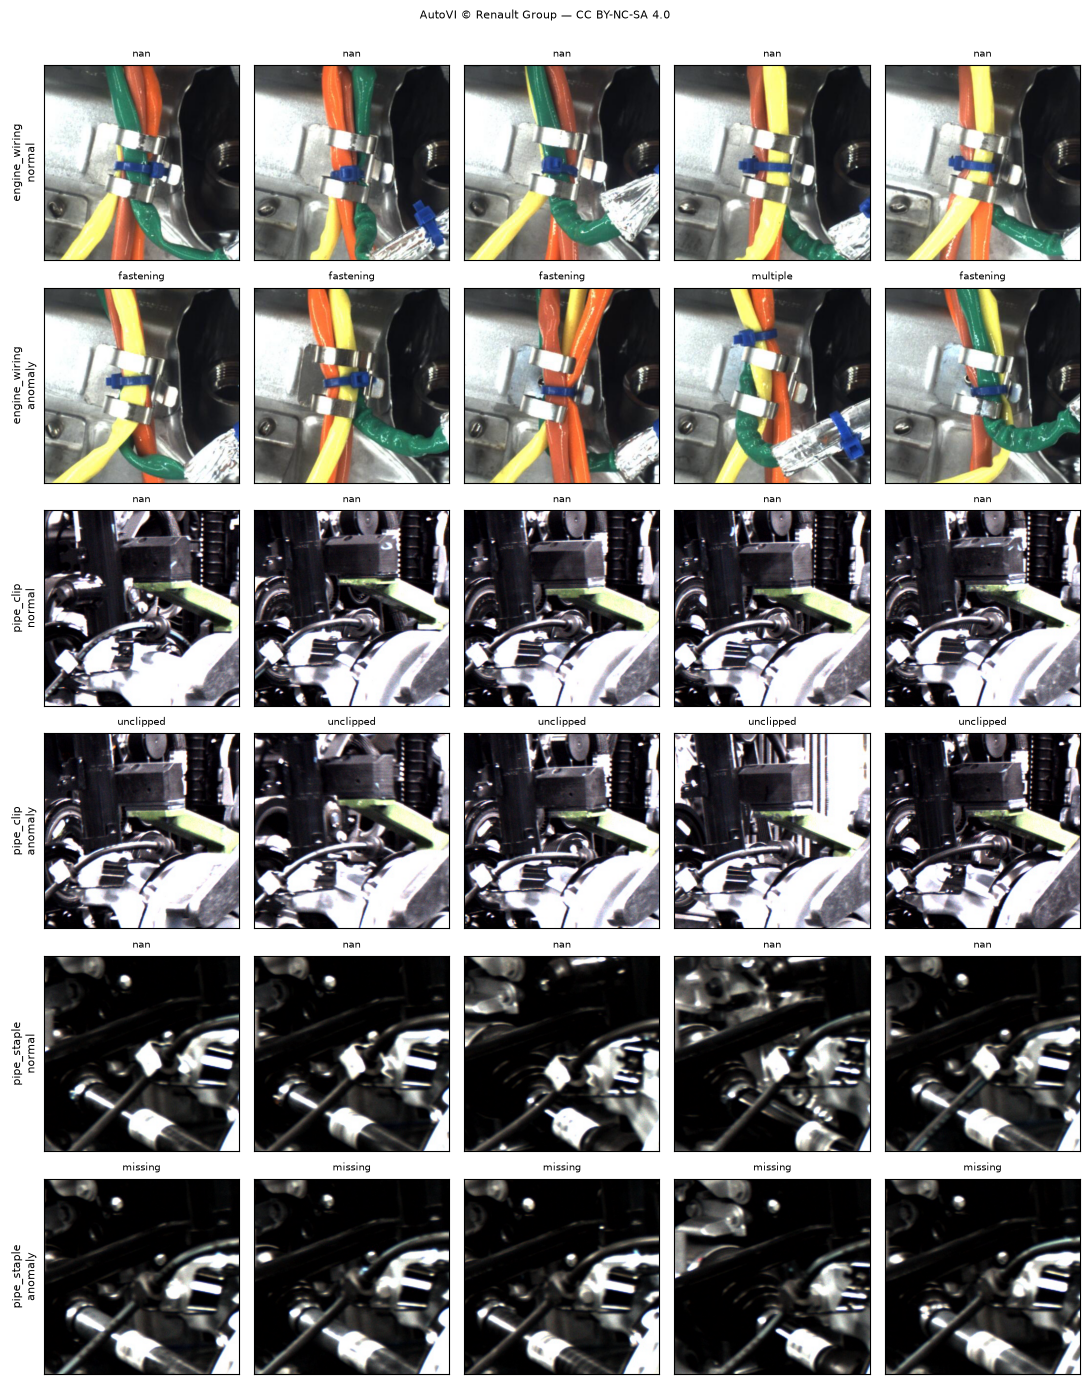

In [19]:
rng = np.random.default_rng(0)
pairs = [(c, l) for c in sorted(df["category"].unique()) for l in ("normal", "anomaly")]

fig, axes = plt.subplots(len(pairs), 5, figsize=(11, 2.3 * len(pairs)))
for r, (cat, lab) in enumerate(pairs):
    sub  = df[(df["category"] == cat) & (df["label"] == lab)]
    pick = rng.choice(sub.index, size=5, replace=False)
    for c in range(5):
        ax = axes[r, c]
        ax.imshow(X[df.index.get_loc(pick[c])])
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(df.loc[pick[c], "defect_type"] or "good", fontsize=7)
    axes[r, 0].set_ylabel(f"{cat}\n{lab}", fontsize=8)
fig.suptitle("AutoVI © Renault Group — CC BY-NC-SA 4.0", fontsize=8, y=1.0)
fig.tight_layout()


### The mean of images and the difference map
 Average all normal images of a client, average all its anomalies, and subtract. Anything that survives averaging is systematic; everything else blurs away.
 The parts have consistent positions, given the clarity of the images mean. The defect is spatially localised and consistent.

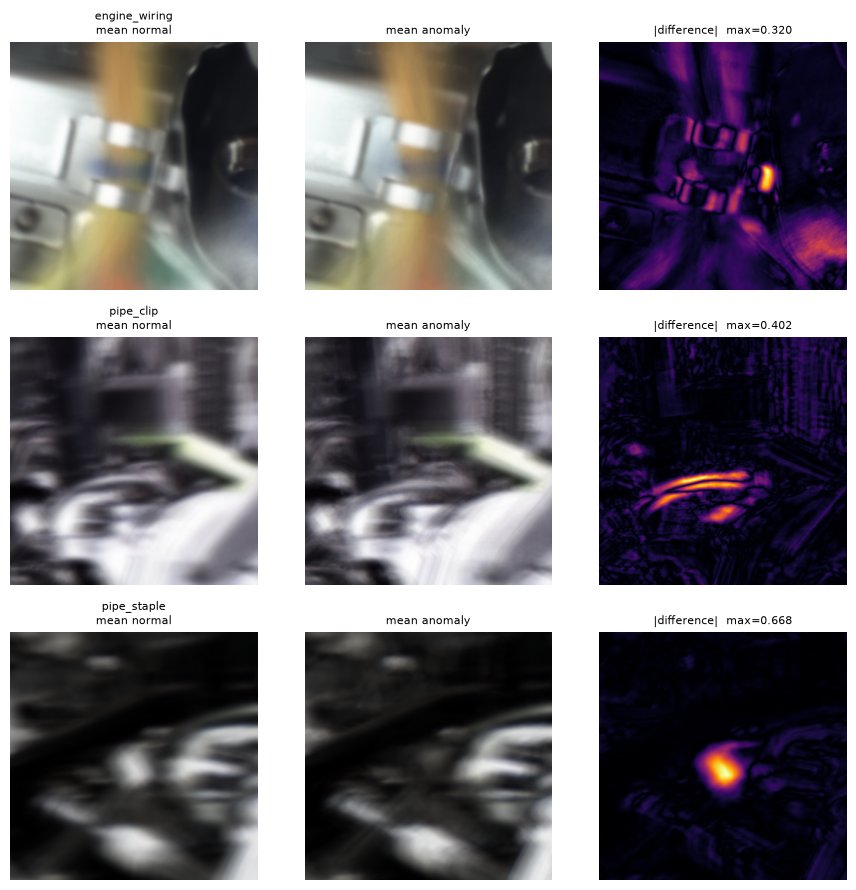

In [18]:
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for r, cat in enumerate(sorted(df["category"].unique())):
    in_cat = (df["category"] == cat).to_numpy()
    mean_n = X[in_cat & (df["label"] == "normal").to_numpy()].mean(axis=0) / 255
    mean_a = X[in_cat & (df["label"] == "anomaly").to_numpy()].mean(axis=0) / 255
    diff   = np.abs(mean_a - mean_n).mean(axis=2)

    for c, (img, title, kw) in enumerate([
        (mean_n, "mean normal",  {}),
        (mean_a, "mean anomaly", {}),
        (diff,   f"|difference|  max={diff.max():.3f}", {"cmap": "inferno"}),
    ]):
        axes[r, c].imshow(img, **kw)
        axes[r, c].axis("off")
        axes[r, c].set_title(f"{cat}\n{title}" if c == 0 else title, fontsize=8)
fig.tight_layout()


### Confirm dedupe
Remove duplicate images from the dataset, keeping only one copy of each unique image. This will help ensure that the dataset is clean and free from redundancy, which can affect model training and evaluation.

In [20]:
import json

npz = np.load(REPO / "data/raw/autovi_npz/autovi_all.npz", allow_pickle=True)
print("npz arrays:", list(npz.keys()))
print("images    :", npz["images"].shape)

n_expected = len(df) - df.duplicated("pixel_md5").sum()
print(f"\nraw images         : {len(df)}")
print(f"minus 73 duplicates: {n_expected}")
print(f"npz images         : {len(npz['images'])}   match = {len(npz['images']) == n_expected}")

print("\nanomaly rate  raw (deduped) vs npz:")
kept = df[~df.duplicated("pixel_md5")]
print(f"  {(kept['label'] == 'anomaly').mean():.4f}  vs  {npz['labels'].mean():.4f}")

print("\nper-category counts:")
print(pd.DataFrame({
    "raw_deduped": kept["category"].value_counts(),
    "npz":         pd.Series(npz["category"]).value_counts(),
}))

summary = json.loads((REPO / "data/raw/autovi_npz/autovi_summary.json").read_text())
print("\nconverter reported duplicates removed:",
      summary["exact_duplicates_removed_total"])


npz arrays: ['images', 'labels', 'category']
images    : (1847, 128, 128, 3)

raw images         : 1920
minus 73 duplicates: 1847
npz images         : 1847   match = True

anomaly rate  raw (deduped) vs npz:
  0.3075  vs  0.3075

per-category counts:
               raw_deduped  npz
engine_wiring          832  832
pipe_clip              519  519
pipe_staple            496  496

converter reported duplicates removed: 73


## Data splitting
We keep the native 400px image size here, matching the EDA half above and the
UPB cluster training runs.


### Group strategy split
First, we split the dataset by the 3 categories of images, in 3 clients

In [1]:
from pathlib import Path
import hashlib, json, subprocess, sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works whether the notebook lives in notebooks/stage_01/ or at the repo root
REPO  = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_splitting").is_dir())
NPZ   = REPO / "data" / "raw" / "autovi_npz" / "autovi_all.npz"
PARTS = REPO / "data" / "partitions" / "autovi"

assert NPZ.is_file(), (
    f"{NPZ} not found. Build it with:\n"
    "  python data_splitting/autovi.py --zips data/raw/autovi/*.zip \\\n"
    "      --out data/raw/autovi_npz --size 400 \\\n"
    "      --merged data/raw/autovi_npz/autovi_all.npz"
)

npz      = np.load(NPZ, allow_pickle=True)
images   = npz["images"]                      # (1847, 400, 400, 3) uint8
labels   = npz["labels"].reshape(-1)          # 0 = normal, 1 = anomaly
category = npz["category"].reshape(-1)        # the production part = the client

summary = json.loads((REPO / "data/raw/autovi_npz/autovi_summary.json").read_text())

print(f"{NPZ.name}: {images.shape} {images.dtype}  ({images.nbytes/1e6:.0f} MB)")
print(f"licence : {summary['licence']}")
print(f"size    : {summary['image_size']}px   mode: {summary['mode']}   seed: {summary['seed']}")
print(f"dupes removed by the converter: {summary['exact_duplicates_removed_total']}")
print(f"anomaly rate: {labels.mean():.4f}")
print("per category:", pd.Series(category).value_counts().to_dict())

# --- Contract checks: the EDA half's headline facts, re-derived from the npz ---
assert len(images) == 1847,                      "expected 1847 images after dedupe"
assert summary["exact_duplicates_removed_total"] == 73
assert summary["image_size"] == 400,             "this half assumes the 400px npz"
assert set(np.unique(labels)) == {0, 1}
assert abs(labels.mean() - 0.3075) < 1e-3,       "anomaly rate moved"
assert len(np.unique(category)) == 3
print("\n✓ npz matches the description half (1847 imgs, 73 dupes removed, 30.75% anomalies)")


autovi_all.npz: (1847, 400, 400, 3) uint8  (887 MB)
licence : CC BY-NC-SA 4.0 (non-commercial, not redistributable)
size    : 400px   mode: supervised   seed: 42
dupes removed by the converter: 73
anomaly rate: 0.3075
per category: {'engine_wiring': 832, 'pipe_clip': 519, 'pipe_staple': 496}

✓ npz matches the description half (1847 imgs, 73 dupes removed, 30.75% anomalies)


Both train and test sets has similar anomaly rate.

In [2]:
# make_test_mask(): a random --test-fraction of the POOL, drawn with --seed
test_mask = np.random.default_rng(42).random(len(labels)) < 0.2

pool_y   = labels[~test_mask]        # labels of the 1465 partitionable images
pool_cat = category[~test_mask]      # their production part

print(f"global test set : {test_mask.sum()} images  (anomaly {labels[test_mask].mean():.4f})")
print(f"pool to split   : {(~test_mask).sum()} images  (anomaly {pool_y.mean():.4f})")
print("pool per category:", pd.Series(pool_cat).value_counts().to_dict())


global test set : 382 images  (anomaly 0.3089)
pool to split   : 1465 images  (anomaly 0.3072)
pool per category: {'engine_wiring': 671, 'pipe_clip': 410, 'pipe_staple': 384}


### Split seed
On the splitting strategy, the partitioning function `group_split` shuffles the group list, then packs groups largest-first onto whichever client is currently smallest.

In [3]:
meta = json.loads((PARTS / "meta.json").read_text())

# Pool sizes per category, reproducing the splitter's test mask exactly
npz   = np.load(REPO / "data/raw/autovi_npz/autovi_all.npz", allow_pickle=True)
y_all, cat_all = npz["labels"].reshape(-1), npz["category"].reshape(-1)
test_mask = np.random.default_rng(42).random(len(y_all)) < 0.2      # == make_test_mask()

pool_cat, pool_y = cat_all[~test_mask], y_all[~test_mask]
pool_sizes = pd.Series(pool_cat).value_counts()

client_total = {c["client"]: c["train"] + c["val"] for c in meta["clients"]}
CLIENT2CAT   = {cid: pool_sizes.index[pool_sizes.to_numpy() == n][0]
                for cid, n in client_total.items()}

print("pool sizes per category:", pool_sizes.to_dict())
print("client -> station      :", CLIENT2CAT)


pool sizes per category: {'engine_wiring': 671, 'pipe_clip': 410, 'pipe_staple': 384}
client -> station      : {0: 'engine_wiring', 1: 'pipe_clip', 2: 'pipe_staple'}


### Statistics per client
Quantity skew - 570 / 348 / 326, a 1.75× spread. FedAvg weights by sample count, so client 0 gets ~46% of the vote.

Label skew - 38.9% / 23.6% / 25.8% anomalies. Client 0 sees defects at 1.6× client 1's rate.

Feature skew - mean brightness 0.471 / 0.426 / 0.195. pipe_staple is photographed at well under half the brightness of the other two stations, and the gap (0.23) is ~7× the within-client spread the EDA half measured (std ≈ 0.03).

Client 0 (0.471) and client 1 (0.426) are moderately lit and fairly close; client 2 (0.195) is much darker. That's a real domain shift: pipe_staple images are shot against a dark background / dark material, so most pixels sit near 0. The spread of pixels (`std_px`) within the images is pretty similar between clients.

In [4]:
rows = []
for c in meta["clients"]:
    cid = c["client"]
    z   = np.load(PARTS / f"client_{cid}.npz")
    g   = z["x_train"].astype(np.float32).mean(axis=3) / 255.0      # greyscale, [0,1]
    rows.append({
        "client":    cid,
        "station":   CLIENT2CAT[cid],
        "n_train":   c["train"],
        "n_val":     c["val"],
        "normal":    c["train_class_counts"][0],
        "anomaly":   c["train_class_counts"][1],
        "anomaly_%": round(100 * c["train_class_counts"][1] / c["train"], 1),
        "mean_px":   round(float(g.mean()), 3),
        "std_px":    round(float(g.std(axis=(1, 2)).mean()), 3),
        "p5":        round(float(np.percentile(g, 5)), 3),
        "p95":       round(float(np.percentile(g, 95)), 3),
    })

per_client = pd.DataFrame(rows).set_index("client")

test = np.load(PARTS / "test.npz")
g_te = test["x_test"].astype(np.float32).mean(axis=3) / 255.0
per_client.loc["TEST"] = {
    "station": "mixed (all 3)", "n_train": len(test["y_test"]), "n_val": 0,
    "normal":  int((test["y_test"] == 0).sum()), "anomaly": int(test["y_test"].sum()),
    "anomaly_%": round(100 * float(test["y_test"].mean()), 1),
    "mean_px": round(float(g_te.mean()), 3),
    "std_px":  round(float(g_te.std(axis=(1, 2)).mean()), 3),
    "p5": round(float(np.percentile(g_te, 5)), 3),
    "p95": round(float(np.percentile(g_te, 95)), 3),
}
per_client


,station,n_train,n_val,normal,anomaly,anomaly_%,mean_px,std_px,p5,p95
client,,,,,,,,,,
0,engine_wiring,570,101,348,222,38.9,0.471,0.307,0.067,0.995
1,pipe_clip,348,62,266,82,23.6,0.426,0.373,0.010,1.000
2,pipe_staple,326,58,242,84,25.8,0.195,0.294,0.000,0.993
TEST,mixed (all 3),382,0,264,118,30.9,0.378,0.321,0.004,0.997


The charts showcase clearly the higher number anomaly images in client 0 (first 2 charts), and the data skews and the similar pizel spread per each client (3rd chart).

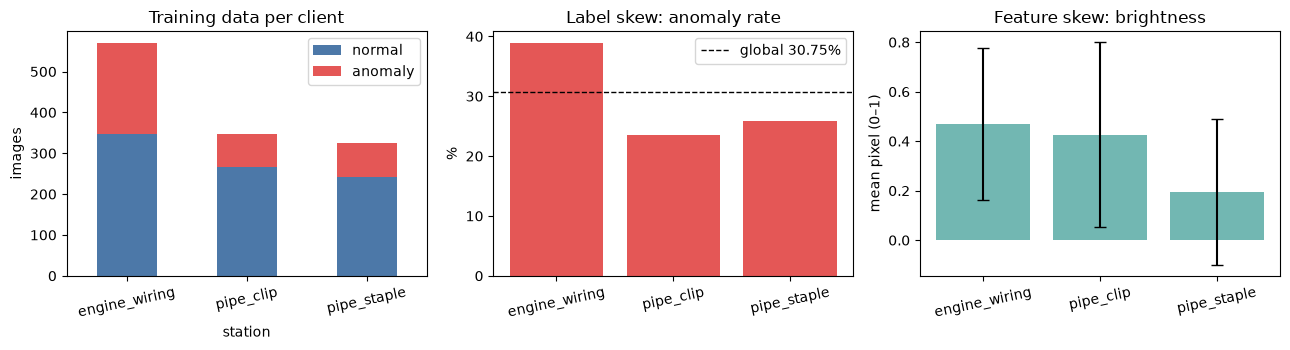

In [5]:
real = per_client.drop("TEST")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))

real.set_index("station")[["normal", "anomaly"]].plot.bar(
    ax=ax[0], stacked=True, color=["#4C78A8", "#E45756"], rot=12)
ax[0].set_title("Training data per client")
ax[0].set_ylabel("images")

ax[1].bar(real["station"], real["anomaly_%"], color="#E45756")
ax[1].axhline(30.75, ls="--", c="k", lw=1, label="global 30.75%")
ax[1].set_title("Label skew: anomaly rate"); ax[1].set_ylabel("%")
ax[1].tick_params(axis="x", rotation=12); ax[1].legend()

ax[2].bar(real["station"], real["mean_px"], yerr=real["std_px"],
          capsize=4, color="#72B7B2")
ax[2].set_title("Feature skew: brightness"); ax[2].set_ylabel("mean pixel (0–1)")
ax[2].tick_params(axis="x", rotation=12)

fig.tight_layout()


### Heterogenity
To measure the heterogenity of the dataset splitting, we use the following metrics:

| Metric | Definition | Measures | Range | Reads as |
|---|---|---|---|---|
| EMD (L1 between label histograms) | minimum work to reshape one histogram into the other; on evenly spaced bins this is `\|p - q\|.sum()` — here, twice the anomaly-rate gap | label skew | 0 … 2 | 0 = client is a perfect miniature of the global set |
| JSD (Jensen–Shannon, log₂) | symmetrised KL against the midpoint `m = (p+q)/2`: `0.5·KL(p‖m) + 0.5·KL(q‖m)`, in bits | label skew | 0 … 1 | safer than KL — finite when a client has zero of a class |
| Gini of client sizes | Gini coefficient of the client sample counts — mean absolute difference between every pair of sizes, normalised by the total | quantity skew | 0 … 1 | 0 = all clients equal |
| Jaccard between client index sets | largest off-diagonal `\|A ∩ B\| / \|A ∪ B\|` over client index-set pairs | replication | 0 … 1 | 0 = true partition |


In [6]:
def label_hist(labels, num_classes=2):
    return np.bincount(labels, minlength=num_classes) / max(len(labels), 1)

def emd(p, q):                      # Wasserstein-1 on a label histogram == L1
    return float(np.abs(p - q).sum())

def jsd(p, q):                       # Jensen-Shannon divergence, log base 2
    m  = (p + q) / 2
    kl = lambda a, b: float(sum(ai * np.log2(ai / bi)
                                for ai, bi in zip(a, b) if ai > 0))
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)

def gini(sizes):                     # 0 = equal sizes, -> 1 = one client holds everything
    x = np.sort(np.asarray(sizes, dtype=float))
    n = len(x)
    return float((2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum()))

def jaccard_matrix(parts):
    n = len(parts)
    M = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            a, b = set(parts[i].tolist()), set(parts[j].tolist())
            M[i, j] = len(a & b) / len(a | b)
    return M

def heterogeneity(parts, labels):
    """One dict of scalars describing how non-IID a list of index arrays is."""
    glob = label_hist(labels)
    hs   = [label_hist(labels[p]) for p in parts]
    emds = [emd(h, glob) for h in hs]
    jsds = [jsd(h, glob) for h in hs]
    J    = jaccard_matrix(parts)
    return {"mean_EMD": np.mean(emds), "max_EMD":  np.max(emds),
            "mean_JSD": np.mean(jsds), "size_Gini": gini([len(p) for p in parts]),
            "max_Jaccard": float(J[~np.eye(len(parts), dtype=bool)].max())}


In [7]:
sys.path.insert(0, str(REPO / "data_splitting"))
from partitioning import (group_split, iid_split, dirichlet_split,
                          quantity_split, pathological_split)

parts_group = group_split(pool_cat, 3, seed=42)
h = heterogeneity(parts_group, pool_y)
print({k: round(v, 4) for k, v in h.items()})


{'mean_EMD': np.float64(0.1387), 'max_EMD': np.float64(0.1547), 'mean_JSD': np.float64(0.0042), 'size_Gini': 0.1306, 'max_Jaccard': 0.0}


The max Jaccard is 0 because the group splitting strategy deliberately left no duplicates between clients.

A `0.1306` Gini and `0.4%` mean JSD show a mild quantity skew, as we can see from the charts above. This measures the importance of client 0 in the FedAvg weights, contributing 1.75 times more ti the training than the other 2 clients.

Since EMD on 2 bins is twice the anomaly-rate gap, mean 0.139 means the average client sits ~6.9 pp off the global anomaly rate, and the worst ~7.7 pp. Around a ~30% global rate, that's clients at roughly 23% and 37%.

### Analyze the Dirichlet α scale
Now we want to measure how differently labelled is a client's data from the population? 0 = perfectly IID, 2 = a client holds only one class. And where the group strategy split stands on the Dirichlet scale.
High α → IID; low α → each client gets almost one class.

In [8]:
ALPHAS = [1000, 100, 50, 20, 10, 5, 2, 1.0, 0.5, 0.2, 0.1]
SEEDS  = range(1, 21)

cal = []
for a in ALPHAS:
    vals = []
    for s in SEEDS:
        try:
            vals.append(heterogeneity(dirichlet_split(pool_y, 3, alpha=a, seed=s),
                                      pool_y)["mean_EMD"])
        except RuntimeError:        # min_samples retry exhausted at very low alpha
            pass
    cal.append({"alpha": a, "mean_EMD": np.mean(vals),
                "std": np.std(vals), "n_seeds": len(vals)})

cal = pd.DataFrame(cal)

# group_split is deterministic given the groups: same partition for every seed
g_emd = h["mean_EMD"]
equiv = cal.iloc[(cal["mean_EMD"] - g_emd).abs().argmin()]["alpha"]

print(cal.round(3).to_string(index=False))
print(f"\ngroup split EMD = {g_emd:.3f}  ->  equivalent to Dirichlet alpha ~ {equiv:g}")


 alpha  mean_EMD   std  n_seeds
1000.0     0.013 0.006       20
 100.0     0.042 0.020       20
  50.0     0.059 0.027       20
  20.0     0.093 0.045       20
  10.0     0.132 0.063       20
   5.0     0.191 0.087       20
   2.0     0.309 0.133       20
   1.0     0.460 0.160       20
   0.5     0.561 0.219       20
   0.2     0.764 0.218       20
   0.1     0.796 0.201       20

group split EMD = 0.139  ->  equivalent to Dirichlet alpha ~ 10


From the table and the chart, we can see the mean_EMD is monotone over α, and rises smoothly up to 0.2 -0.1, where it plateaus, as the client distribution becomes near-pathological. The groups strategy split corresponds to `α = 10`, given mean EMD `0.1387` compared to `0.132` from the Dirichlet split.

Moreover, the standard deviation is not inverse proportional with α, soaring until 0.5 (0.0064 → 0.2185) and then drops back at α = 0.2 and 0.1 (0.218, 0.201). Once a client has only anomalies or only normals, it can't get any more extreme. So it stops varying between seeds.

Note:

High α (1000, 100, 10): cards are dealt fairly. Every client ends up close to the global 31% anomaly rate. Small differences between seeds → small std.

Middle α (2, 1, 0.5): dealing is unfair, and unpredictably so. One seed gives you a client at 50% anomalies, another seed gives you one at 5%. Lots of variation between seeds → big std. This is the peak.

Low α (0.2, 0.1): dealing is so unfair that most clients just get all of one kind. And here's the thing — "all anomalies" is as extreme as it gets. You can't be more-than-all. Seed 3 gives you a client with all anomalies, seed 7 gives you a client with all anomalies, seed 12 the same. They're all identical now. No variation left → std drops.

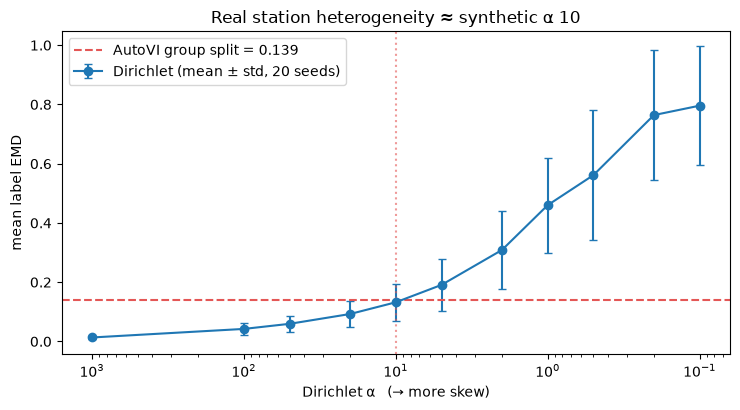

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.errorbar(cal["alpha"], cal["mean_EMD"], yerr=cal["std"],
            marker="o", capsize=3, label="Dirichlet (mean ± std, 20 seeds)")
ax.axhline(g_emd, color="#E45756", ls="--",
           label=f"AutoVI group split = {g_emd:.3f}")
ax.axvline(equiv, color="#E45756", ls=":", alpha=0.6)
ax.set_xscale("log"); ax.invert_xaxis()
ax.set_xlabel("Dirichlet α   (→ more skew)")
ax.set_ylabel("mean label EMD")
ax.set_title(f"Real station heterogeneity ≈ synthetic α {equiv:g}")
ax.legend()
fig.tight_layout()


### Sweep every strategy and build the comparison table

The table below measures how much difficulty non-IID pose for our Federated Learning future training.

In [11]:
CONFIGS = [
    ("iid",          "—",     lambda s: iid_split(pool_y, 3, seed=s)),
    ("dirichlet",    "α=100", lambda s: dirichlet_split(pool_y, 3, alpha=100, seed=s)),
    ("dirichlet",    "α=1.0", lambda s: dirichlet_split(pool_y, 3, alpha=1.0, seed=s)),
    ("dirichlet",    "α=0.5", lambda s: dirichlet_split(pool_y, 3, alpha=0.5, seed=s)),
    ("dirichlet",    "α=0.1", lambda s: dirichlet_split(pool_y, 3, alpha=0.1, seed=s)),
    ("quantity",     "α=0.5", lambda s: quantity_split(pool_y, 3, alpha=0.5, seed=s)),
    ("quantity",     "α=0.1", lambda s: quantity_split(pool_y, 3, alpha=0.1, seed=s)),
    ("pathological", "K=1",   lambda s: pathological_split(pool_y, 3, classes_per_client=1, seed=s)),
    ("group",        "real",  lambda s: group_split(pool_cat, 3, seed=s)),
]

sweep = []
for name, knob, make in CONFIGS:
    parts = make(42)
    row = {"strategy": name, "knob": knob}
    row.update(heterogeneity(parts, pool_y))
    row["sizes"]    = str([len(p) for p in parts])
    row["anomaly_%"] = str([round(100 * float(pool_y[p].mean()), 1) for p in parts])
    sweep.append(row)

sweep = pd.DataFrame(sweep).round(3)
sweep


,strategy,knob,mean_EMD,max_EMD,mean_JSD,size_Gini,max_Jaccard,sizes,anomaly_%
0,iid,—,0.028,0.041,0.000,0.000,0.0,"[489, 488, 488]","[29.7, 32.8, 29.7]"
1,dirichlet,α=100,0.045,0.066,0.000,0.008,0.0,"[491, 496, 478]","[32.2, 27.4, 32.6]"
2,dirichlet,α=1.0,0.387,0.765,0.045,0.229,0.0,"[375, 293, 797]","[34.7, 68.9, 14.8]"
3,dirichlet,α=0.5,0.239,0.437,0.022,0.350,0.0,"[516, 90, 859]","[40.9, 8.9, 26.9]"
4,dirichlet,α=0.1,0.554,0.733,0.078,0.388,0.0,"[591, 863, 11]","[67.3, 5.9, 9.1]"
5,quantity,α=0.5,0.091,0.261,0.006,0.396,0.0,"[561, 887, 17]","[31.2, 30.7, 17.6]"
6,quantity,α=0.1,0.149,0.433,0.018,0.481,0.0,"[385, 1069, 11]","[31.4, 30.7, 9.1]"
7,pathological,K=1,1.129,1.386,0.382,0.359,0.0,"[225, 1015, 225]","[100.0, 0.0, 100.0]"
8,group,real,0.139,0.155,0.004,0.131,0.0,"[671, 410, 384]","[38.5, 24.1, 24.2]"


| Row | What it is | Read it as |
|---|---|---|
| **0 `iid`** | Shuffle and cut in 3 | The control. Everything ~0. Sizes equal, anomaly rates all ~30%. FedAvg should match centralised training here. |
| **1 `dirichlet` α=100** | Dirichlet with a huge α | Also basically IID. α=100 is a sanity check that the Dirichlet code reduces to IID when α is large. It does. |
| **2–4 `dirichlet` α=1.0 / 0.5 / 0.1** | The standard FL non-IID knob | Smaller α = more extreme. Skews **both** labels and sizes at once. |
| **5–6 `quantity` α=0.5 / 0.1** | Only sizes are skewed | `mean_EMD` stays low (0.09, 0.15) but Gini is high (0.40, 0.48). Clients see the *same* problem, just wildly different amounts of data. Isolates one variable. |
| **7 `pathological` K=1** | Worst case by construction | Each client gets 1 class only. `anomaly_%` = [100, 0, 100] — client 2 has literally never seen a defect. EMD 1.386, JSD 0.382, both near their ceilings. This is the "FedAvg should break here" row. |
| **8 `group` real** | Split by actual machine/station in AutoVI | The realistic one. Mild: EMD 0.139 (~7 pp off), Gini 0.13. Everything else is synthetic difficulty; this is the difficulty the real data actually has. |

### Reproducibility across seeds
In short, the α=0.5 and α=0.1 configurations are markedly less reproducible than the remaining rows. At α=0.1 the standard deviation is 0.325 against a mean of 0.822, so an individual draw typically falls within roughly ±40% of the mean.

In [12]:
multi = []
for name, knob, make in CONFIGS:
    vals = []
    for s in (1, 2, 3):
        try: vals.append(heterogeneity(make(s), pool_y)["mean_EMD"])
        except RuntimeError: pass
    multi.append({"strategy": name, "knob": knob,
                  "EMD_mean": np.mean(vals), "EMD_std": np.std(vals)})
pd.DataFrame(multi).round(3)


,strategy,knob,EMD_mean,EMD_std
0,iid,—,0.034,0.002
1,dirichlet,α=100,0.050,0.011
2,dirichlet,α=1.0,0.451,0.092
3,dirichlet,α=0.5,0.674,0.163
4,dirichlet,α=0.1,0.822,0.325
5,quantity,α=0.5,0.102,0.053
6,quantity,α=0.1,0.156,0.045
7,pathological,K=1,0.957,0.121
8,group,real,0.139,0.000


### Verify the split did not break anything
Is any client's image also in the test set? No overlap between the clients.

In [13]:
import hashlib

X_all = npz["images"]
by_hash = {}
for i, im in enumerate(X_all):
    by_hash.setdefault(hashlib.md5(im.tobytes()).hexdigest(), []).append(i)

def source_ids(arr):
    """Map written images back to their row in autovi_all.npz."""
    return [by_hash[hashlib.md5(im.tobytes()).hexdigest()][0] for im in arr]

owned = {}
for cid in CLIENT2CAT:
    z = np.load(PARTS / f"client_{cid}.npz")
    owned[cid] = set(source_ids(z["x_train"])) | set(source_ids(z["x_val"]))

test_ids  = set(source_ids(np.load(PARTS / "test.npz")["x_test"]))
all_owned = set().union(*owned.values())

print(f"train/val ∩ test              : {len(all_owned & test_ids)}      (must be 0)")
for i in owned:
    for j in owned:
        if i < j:
            print(f"client {i} ∩ client {j}            : {len(owned[i] & owned[j])}      (must be 0)")
print(f"coverage: clients ∪ test      : {len(all_owned | test_ids)} / {len(X_all)}")

# And the test set really is mixed across stations, as Step 14 claimed
print("\ntest-set composition:",
      pd.Series(cat_all[sorted(test_ids)]).value_counts().to_dict())

assert not (all_owned & test_ids),            "LEAKAGE: a client holds a test image"
assert len(all_owned | test_ids) == len(X_all), "some images went missing"
print("\n✓ no leakage, no client overlap, full coverage")


train/val ∩ test              : 0      (must be 0)
client 0 ∩ client 1            : 0      (must be 0)
client 0 ∩ client 2            : 0      (must be 0)
client 1 ∩ client 2            : 0      (must be 0)
coverage: clients ∪ test      : 1847 / 1847

test-set composition: {'engine_wiring': 161, 'pipe_staple': 112, 'pipe_clip': 109}

✓ no leakage, no client overlap, full coverage


### Alternative partitions
| folder | train sizes | class counts | note |
|---|---|---|---|
| `autovi` | 570 / 348 / 326 | [348,222] [266,82] [242,84] | every client sees both classes |
| `autovi_iid` | 416 / 415 / 415 | [296,120] [286,129] [293,122] | the control: near-identical mixes |
| `autovi_dir_a1.0` | 319 / 249 / 677 | [210,109] [78,171] [572,105] | client 1 is anomaly-majority — inverted vs global |
| `autovi_dir_a0.1` | 373 / 813 / 59 | [0,373] [813,0] [50,9] | two degenerate clients |


In [14]:
RUNS = [
    ("autovi",            ["--strategy", "group", "--group-col", "category"]),
    ("autovi_iid",        ["--strategy", "iid"]),
    ("autovi_dir_a1.0",   ["--strategy", "dirichlet", "--alpha", "1.0"]),
    ("autovi_dir_a0.1",   ["--strategy", "dirichlet", "--alpha", "0.1"]),
]

for name, extra in RUNS:
    out = REPO / "data" / "partitions" / name
    if (out / "meta.json").exists():
        print(f"skip  {name}  (already built)")
        continue
    r = subprocess.run(
        [sys.executable, str(REPO / "data_splitting" / "split_data.py"),
         "--input", str(REPO / "data/raw/autovi_npz/autovi_all.npz"),
         "--num-clients", "3", "--class-names", "normal,anomaly",
         "--seed", "42", "--out", str(out), *extra],
        capture_output=True, text=True)
    print(f"{'ok   ' if r.returncode == 0 else 'FAIL '} {name}")
    if r.returncode:
        print(r.stdout[-1500:], r.stderr[-1500:])


skip  autovi  (already built)
ok    autovi_iid
ok    autovi_dir_a1.0
ok    autovi_dir_a0.1


### Summary

We partitioned 1847 AutoVI images (1920 raw, minus 73 exact duplicates) across 3 clients. The
production part (`category`) is the client, so this is a real federation boundary
rather than a synthetic one. The partitions live in `data/partitions/autovi`, seed 42.

The group split scores `mean_EMD = 0.139`, which puts every client around 7 pp off the
global 31% anomaly rate, with both classes present everywhere. Calibrated against the
Dirichlet scale over 20 seeds, that sits at `α ≈ 10`. Real station heterogeneity is
mild, and FedAvg should not collapse on it.

The other three partitions answer a different question. `autovi_iid` is the control,
and `autovi_dir_a1.0` and `autovi_dir_a0.1` are stress tests at an α far below anything
the real data shows. At `α = 0.1` two clients hold a single class each. They tell us
where FedAvg breaks, not what deployment looks like.

Note:

Dirichlet at `α ≤ 0.5` varies a lot between seeds (std `0.163` and `0.325`), so any
result at those settings needs several seeds and error bars.

The dataset is imbalanced at 31% anomalies, so we report balanced accuracy and
macro-F1, not raw accuracy.

The centralised baseline below is one seed. Its `std = 0.000` means unmeasured, not
reproducible.

We verified there is no train/val/test leakage, no image shared between clients
(`max_Jaccard = 0.0` on every strategy), and the clients plus test set cover the whole
deduplicated pool.


In [17]:
# Fairness numbers from the centralised baseline.
# `summary` earlier in this notebook is autovi_summary.json, so use a distinct
# name and (re)generate summary.json first -- summarize.py writes both the
# accuracy and the balanced-accuracy worst-client keys.
EXP = REPO / "outputs" / "experiments" / "member1-centralised"

subprocess.run([sys.executable, str(REPO / "experiments" / "summarize.py"), str(EXP)],
               check=True, capture_output=True, text=True)

exp_summary = json.loads((EXP / "summary.json").read_text())

worst = pd.DataFrame(
    [{"metric": m,
      "mean": exp_summary[f"val_worst_client_{m}"]["mean"],
      "std":  exp_summary[f"val_worst_client_{m}"]["std"],
      "seeds": len(exp_summary["seeds"])}
     for m in ("accuracy", "balanced_accuracy")]
).round(4)

print(f"{EXP.name}: {len(exp_summary['seeds'])} seed(s) -> {exp_summary['seeds']}")
worst


member1-centralised: 1 seed(s) -> ['seed1']


,metric,mean,std,seeds
0,accuracy,0.8515,0.0,1
1,balanced_accuracy,0.8350,0.0,1


In [18]:
handoff = (sweep[["strategy", "knob", "mean_EMD", "max_EMD", "mean_JSD",
                  "size_Gini", "sizes", "anomaly_%"]].copy())

folder = {("group", "real"): "autovi", ("iid", "—"): "autovi_iid",
          ("dirichlet", "α=1.0"): "autovi_dir_a1.0",
          ("dirichlet", "α=0.1"): "autovi_dir_a0.1"}
handoff["partition_dir"] = [folder.get((s, k), "") for s, k in
                            zip(handoff["strategy"], handoff["knob"])]

# Columns Members 2 and 3 fill in. Names mirror summarize.py's keys so the join is trivial.
for col in ("centralised_bal_acc", "federated_bal_acc", "fl_gap",
            "worst_client_bal_acc",     # <- the fairness column we report
            "worst_client_acc"):        # <- the footnote, for like-with-like comparison
    handoff[col] = np.nan

# Seed the group row with what we already measured centrally, so the handoff CSV
# ships one filled example rather than an all-NaN template.
is_group = handoff["partition_dir"] == "autovi"
handoff.loc[is_group, "worst_client_acc"] = exp_summary["val_worst_client_accuracy"]["mean"]
handoff.loc[is_group, "worst_client_bal_acc"] = exp_summary["val_worst_client_balanced_accuracy"]["mean"]

out = REPO / "outputs" / "tables"
out.mkdir(parents=True, exist_ok=True)
handoff.to_csv(out / "stage1_split_heterogeneity.csv", index=False)
print(f"wrote {out / 'stage1_split_heterogeneity.csv'}")
handoff[handoff["partition_dir"] != ""]


wrote /home/alex/Industrial-Anomaly-Detection/outputs/tables/stage1_split_heterogeneity.csv


,strategy,knob,mean_EMD,max_EMD,mean_JSD,size_Gini,sizes,anomaly_%,partition_dir,centralised_bal_acc,federated_bal_acc,fl_gap,worst_client_bal_acc,worst_client_acc
0,iid,—,0.028,0.041,0.000,0.000,"[489, 488, 488]","[29.7, 32.8, 29.7]",autovi_iid,NaN,NaN,NaN,NaN,NaN
2,dirichlet,α=1.0,0.387,0.765,0.045,0.229,"[375, 293, 797]","[34.7, 68.9, 14.8]",autovi_dir_a1.0,NaN,NaN,NaN,NaN,NaN
4,dirichlet,α=0.1,0.554,0.733,0.078,0.388,"[591, 863, 11]","[67.3, 5.9, 9.1]",autovi_dir_a0.1,NaN,NaN,NaN,NaN,NaN
8,group,real,0.139,0.155,0.004,0.131,"[671, 410, 384]","[38.5, 24.1, 24.2]",autovi,NaN,NaN,NaN,0.835043,0.851485


# References
Provost, F. (2000). Machine learning from imbalanced data sets 101: Extended abstract. AAAI'2000 Workshop on Imbalanced Data Sets. https://pages.stern.nyu.edu/fprovost/Papers/skew.PDF

McMahan, H. B., Moore, E., Ramage, D., Hampson, S., & Arcas, B. A. y. (2017). Communication-Efficient Learning of Deep Networks from Decentralized Data. Proceedings of the 20th International Conference on Artificial Intelligence and Statistics (AISTATS), PMLR 54, 1273–1282. https://proceedings.mlr.press/v54

Kairouz, P., McMahan, H. B., Avent, B., et al. (2021). Advances and Open Problems in Federated Learning. Foundations and Trends in Machine Learning, 14(1–2), 1–210. https://arxiv.org/abs/1912.04977

Hsu, T.-M. H., Qi, H., & Brown, M. (2019). Measuring the Effects of Non-Identical Data Distribution for Federated Visual Classification. arXiv:1909.06335. https://arxiv.org/abs/1909.06335